# A climate model across latitude
## Week 6: build a model, compare with Earth, then add processes

Start with the EBM from earlier lectures. Give each latitude its own annual mean sunlight, retaining **constant albedo 0.30**, **atmospheric emissivity 0.779**, and **no horizontal transport**. Integrate forward to obtain a temperature profile, then compare its temperature and TOA budgets with Earth.

First use Stefan–Boltzmann radiation with temperatures in kelvin. Add horizontal transport while keeping that radiation law and albedo unchanged. Later introduce prescribed latitude-dependent albedo and linear OLR as separate modeling choices.

All code is supplied. Run the cells and use the figures to answer one question after each discussion. Each band has the same heat capacity per area, corresponding to a 10 m water layer. We omit seasonal forcing, evolving ice, and a separate CO₂ perturbation. References appear at the end.

Write your responses in the answer spaces under **Lab questions** after each discussion.

## 1. Our earlier EBM at every latitude

$Q(\phi)$ is **incoming sunlight at the top of the atmosphere per unit area**, in W m⁻², averaged over a full year, including day/night and seasonal cycles. Sunlight arrives more directly at low latitudes, so annual incoming sunlight is greater near the equator than near the poles.

The supplied function calculates this profile from solar geometry. For an explanation of the calculation, see [Brian Rose's insolation notebook](https://brian-rose.github.io/ClimateLaboratoryBook/courseware/insolation/).

First inspect $Q(\phi)$. Next, apply the one-layer greenhouse model to each latitude band.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve
from scipy.integrate import solve_ivp

%matplotlib inline
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})
SECONDS_PER_YEAR = 365.25 * 86400
R_EARTH = 6.371e6
RHO_CP = 1000.0 * 4180.0  # water density times specific heat: J/m³/K

# Ninety 2-degree latitude bands, from the South Pole to the North Pole.
phi_edges = np.linspace(-np.pi/2, np.pi/2, 91)
phi = 0.5 * (phi_edges[:-1] + phi_edges[1:])
lat, lat_edges = np.rad2deg(phi), np.rad2deg(phi_edges)
band_area = 2*np.pi*R_EARTH**2 * np.diff(np.sin(phi_edges))
weights = band_area / band_area.sum()

def global_mean(values):
    '''Area-weighted mean along the last (latitude) dimension.'''
    return np.asarray(values) @ weights

def annual_sunlight(phi, solar_constant=1361.0, tilt_deg=23.44):
    '''Daily solar geometry averaged over a circular orbit (720 phases).'''
    longitude = 2*np.pi*(np.arange(720) + 0.5)/720
    delta = np.arcsin(np.sin(np.deg2rad(tilt_deg))*np.sin(longitude))
    p = np.asarray(phi)[:, None]
    sunset = np.arccos(np.clip(-np.tan(p)*np.tan(delta), -1, 1))
    daily = solar_constant/np.pi * (
        sunset*np.sin(p)*np.sin(delta)
        + np.cos(p)*np.cos(delta)*np.sin(sunset))
    return np.maximum(daily, 0).mean(axis=1)

Q = annual_sunlight(phi)
FIGURES = {}
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.plot(lat, Q, color='#777777', lw=2)
ax.set(xlabel='Latitude (°)', ylabel='Annual mean incoming Q (W/m²)', xlim=(-90, 90))
FIGURES['incoming_sunlight'] = fig
plt.show()
print(f'Global mean incoming sunlight: {global_mean(Q):.2f} W/m²')

### Independent latitude bands with a one-layer greenhouse model

**Absorbed sunlight:** We assume planetary albedo is **constant with latitude**, with $a_0=0.30$:

$$\mathrm{ASR}(\phi)=(1-a_0)Q(\phi).$$

Each band absorbs 70% of its incoming sunlight.

**Outgoing infrared:** From the one-layer greenhouse model,

$$\mathrm{OLR}(\phi)=(1-\epsilon/2)\sigma T_s^4.$$

Here $\epsilon=0.779$ is the atmospheric layer's longwave absorptivity/emissivity, $T_s$ is the surface temperature of that band in kelvin, and $\sigma=5.670374419\times10^{-8}$ W m⁻² K⁻⁴. The atmosphere adjusts rapidly, with $T_a^4=T_s^4/2$.

**Net radiation and temperature change:** The **net downward radiation at the top of the atmosphere (TOA)** is

$$N(\phi)=\mathrm{ASR}(\phi)-\mathrm{OLR}(\phi).$$

Positive $N$ adds energy to the band; negative $N$ removes energy. ASR, OLR, and $N$ are all in W m⁻². Each band's temperature changes according to

$$C\frac{\partial T_s}{\partial t}=N
=(1-a_0)Q(\phi)-(1-\epsilon/2)\sigma T_s^4.$$

$C$ is heat capacity per unit area, in J m⁻² K⁻¹.

We integrate forward in time to find the **equilibrium temperature at each latitude**, where temperature stops changing. We start every band at 288 K; this is an **arbitrary initial condition**.

In [ ]:
SIGMA = 5.670374419e-8
EPSILON = 0.779

def gray_olr(T_K, epsilon=EPSILON):
    return (1 - epsilon/2)*SIGMA*np.asarray(T_K)**4

def simulate_gray(D=0.0, albedo_value=0.30, epsilon=EPSILON,
                  years=30.0, water_depth=10.0, initial_K=288.0):
    C = RHO_CP*water_depth
    reflect = np.broadcast_to(np.asarray(albedo_value, dtype=float), lat.shape)
    if not (0 <= epsilon <= 1 and np.all((reflect >= 0) & (reflect <= 1))):
        raise ValueError('Emissivity and albedo must lie between 0 and 1.')
    if D < 0 or min(years, water_depth, initial_K) <= 0:
        raise ValueError('Use nonnegative D and positive time, depth and temperature.')
    absorbed = (1-reflect)*Q
    def rhs(t, T_K):
        h = np.zeros_like(T_K) if D == 0 else transport(T_K, D)[1]
        return SECONDS_PER_YEAR/C*(absorbed-gray_olr(T_K, epsilon)+h)
    time = np.linspace(0, years, 301)
    solution = solve_ivp(rhs, (0, years), np.full(len(lat), initial_K),
                         t_eval=time, method='BDF', rtol=1e-9, atol=1e-10)
    if not solution.success:
        raise RuntimeError(solution.message)
    return dict(time=time, T_K=solution.y.T, T=solution.y.T-273.15,
                D=D, C=C, ASR=absorbed, epsilon=epsilon)

# Calculate the independent-band model: D=0 turns horizontal transport off.
gray_no_transport = simulate_gray(D=0.0)
N_gray = gray_no_transport['ASR']-gray_olr(gray_no_transport['T_K'][-1])

# Plot temperature adjustment (left) and final net TOA radiation (right).
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout='constrained')
for target in [0, 0.3, 1, 30]:
    i = np.argmin(np.abs(gray_no_transport['time']-target))
    axes[0].plot(lat, gray_no_transport['T'][i], lw=2,
                 label=f"{gray_no_transport['time'][i]:g} yr")
axes[0].set(xlabel='Latitude (°)', ylabel='Surface temperature (°C)', xlim=(-90, 90))
axes[0].legend()

axes[1].plot(lat, N_gray, color='#555555', lw=2)
axes[1].set(xlabel='Latitude (°)', ylabel='Final net TOA radiation N (W/m²)',
            xlim=(-90, 90), ylim=(-10, 10))
axes[1].axhline(0, color='black', lw=0.7)
FIGURES['gray_no_transport'] = fig
plt.show()

# Report the equilibrium checks.
print(f'Maximum final |N|: {np.max(np.abs(N_gray)):.2e} W/m²')
print(f'Final mean surface temperature: {global_mean(gray_no_transport["T"][-1]):.2f} °C')

<a id="response-1"></a>

**Lab questions**

What must net TOA radiation $N$ be at equilibrium in each independent latitude band?

**Answer:** [Your answer here.]

## 2. Compare the first model with Earth

Compare with annual mean surface **skin temperature** from NCEP–NCAR reanalysis (1981–2010). Load NOAA's public monthly NetCDF files, average over longitude, and then average the months using their calendar lengths. These are reanalysis estimates, rather than direct observations of a single year.

The supplied `data/ncep` folder contains the original temperature file, so class can run offline. If it is missing, the cell downloads it from NOAA and keeps a local copy. Xarray and netCDF4 are required in addition to the modeling packages. The temperature file is about 0.7 MB.

In [ ]:
from pathlib import Path
from urllib.request import urlopen
import xarray as xr

# Keep the public NOAA temperature file locally for offline classes.
DATA_DIR = Path('data/ncep')
DATA_DIR.mkdir(parents=True, exist_ok=True)
NOAA_BASE = 'https://downloads.psl.noaa.gov/Datasets/ncep.reanalysis.derived/'
NCEP_FILES = {
    'temperature_C': ('surface_gauss/skt.sfc.mon.1981-2010.ltm.nc', 'skt'),
}

def cached_ncep_file(relative_url):
    local = DATA_DIR / Path(relative_url).name
    if not local.exists():
        temporary = local.with_suffix('.nc.part')
        try:
            with urlopen(NOAA_BASE + relative_url, timeout=45) as response:
                temporary.write_bytes(response.read())
            # Check that the download is readable before adding it to the cache.
            with xr.open_dataset(temporary, engine='netcdf4', decode_times=False):
                pass
            temporary.replace(local)
        except Exception as error:
            temporary.unlink(missing_ok=True)
            raise RuntimeError(
                f'Could not load {local.name}. Connect to the internet once, '
                'or copy the supplied data/ncep folder beside this notebook.'
            ) from error
    return local

ncep_fields = {}
for name, (relative_url, variable) in NCEP_FILES.items():
    with xr.open_dataset(cached_ncep_file(relative_url),
                         engine='netcdf4', decode_times=False) as source:
        # Dates are climatological months, not a time series of individual years.
        # Label the January--December axis explicitly. Temperatures are in °C.
        field = source[variable].astype('float64').rename(time='month')
        field = field.assign_coords(month=np.arange(1, 13))
        ncep_fields[name] = field.load()

ncep_monthly = xr.merge(
    [field.to_dataset(name=name) for name, field in ncep_fields.items()],
    join='exact')
month_days = xr.DataArray(
    [31, 28 + 7/30, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31],
    dims='month', coords={'month': np.arange(1, 13)})

# Zonal mean first, then an annual mean weighted by calendar month length.
# February includes the seven leap years in the 1981--2010 period.
ncep_annual = (ncep_monthly.mean('lon').weighted(month_days)
               .mean('month').sortby('lat'))

OBS_LAT = ncep_annual.lat.values
OBS_T_C = ncep_annual.temperature_C.values
print('Loaded temperature: 12 climatological months × 94 latitudes × 192 longitudes.')
print('Period: 1981–2010. The original NetCDF file is cached locally.')

In [ ]:
fig, ax = plt.subplots(figsize=(7.6, 4.5), layout='constrained')
ax.plot(lat, gray_no_transport['T'][-1], color='#c54b26', lw=2,
        label='Independent bands: earlier EBM')
ax.plot(OBS_LAT, OBS_T_C, color='#2374a5', lw=2, label='NCEP reanalysis: 1981–2010')
ax.set(xlabel='Latitude (°)', ylabel='Surface skin temperature (°C)', xlim=(-90, 90))
ax.legend(fontsize=9)
FIGURES['gray_temperature_comparison'] = fig
plt.show()

**Reading the comparison:** The model captures the broad pattern of warm tropics and cold poles. It is too warm in the tropics, too cold near the North Pole, and too warm near the South Pole. Its symmetric profile misses Earth's differences between hemispheres. The model also omits Antarctica's high elevation, which contributes to its cold interior. Missing elevation is a likely contributor to the model's warm bias near the South Pole.

### Evidence for heat exchange between latitudes

Temperature differences alone do not identify which missing process causes a model error. The radiation budget provides a direct test of the independent-band assumption: at equilibrium, each band must balance absorbed sunlight with outgoing infrared. We compare that requirement with CERES satellite measurements below.

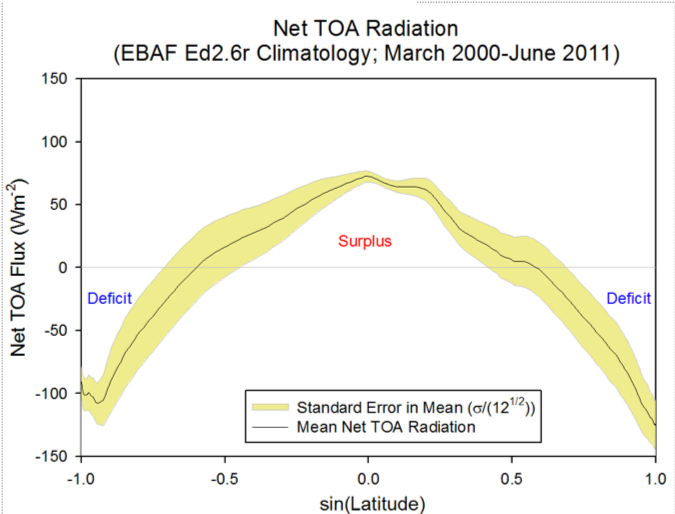

*Source: [NASA CERES Science](https://ceres.larc.nasa.gov/science/), [original figure](https://ceres.larc.nasa.gov/images/NetTOARadiation.png). CERES EBAF Edition 2.6r climatology, March 2000–June 2011.*

The horizontal axis is $\sin\phi$, so the equator is 0 and the poles are −1 and +1. Net downward radiation is $N=\mathrm{ASR}-\mathrm{OLR}$.

Isolated equilibrium bands require **N=0 everywhere**, as shown in the right-hand panel of the temperature-and-radiation figure in **Section 1**. The CERES climatology shows tropical radiative surpluses and higher-latitude deficits. For approximately steady regional temperatures, these require exported and imported energy. Storage can also be nonzero, so exact local equilibrium is an idealization.

**Caveat:** The temperature and radiation datasets cover different periods. We use them to compare broad climate patterns; they do not provide a combined energy budget for the same years.

<a id="response-2"></a>

**Lab questions**

What process can carry energy from regions with a radiative surplus to regions with a radiative deficit?

**Answer:** [Your answer here.]

## 3. Add horizontal transport

Let $H(\phi)$ be the **total rate of heat transfer across the entire latitude circle** at $\phi$, representing the atmosphere and ocean together. **Reminder:** a rate of energy transfer is power, with **1 W = 1 joule per second**. We often express heat transport in petawatts: **1 PW = $10^{15}$ W**.

We choose **northward heat transfer as positive**:

- $H>0$: net heat transfer northward.
- $H<0$: net heat transfer southward.

For example, $H=+1$ PW at 30°N means $10^{15}$ joules cross that latitude circle northward each second. At 30°S, $H=-1$ PW means the same rate southward. Both examples describe poleward heat transport.

**From temperature differences to heat transport:** We approximate the combined effect of winds and ocean currents by diffusion: heat moves from warmer bands toward colder bands. At the boundary between two bands, we use

$$H_{edge}=-2\pi R^2\cos\phi_{edge}\,D\,
\frac{T_{north}-T_{south}}{\phi_{north}-\phi_{south}}.$$

Each part has a role:

- $(T_{north}-T_{south})/(\phi_{north}-\phi_{south})$ is the temperature gradient, estimated from the two neighboring band centers. The denominator is positive because latitude increases northward.
- $D\geq0$ controls how strongly the atmosphere and ocean transfer heat for a given gradient. Its units are W m⁻² K⁻¹. Larger $D$ gives stronger transport; $D=0$ gives none.
- $R$ is Earth's radius. The latitude circle has length $2\pi R\cos\phi_{edge}$. The $R^2$ in the final formula comes from the definition of $D$, as shown below.
- The **minus sign** makes the transport go from warm to cold. If the northern band is colder, the gradient is negative, so $H>0$ and heat moves northward. If the northern band is warmer, $H<0$ and heat moves southward.

<div class="optional-reading" style="border: 1px solid #cbd5e1; background: #f8fafc; padding: 12px 16px; border-radius: 6px; margin: 16px 0;">

**Optional reading: why $2\pi R^2$ appears**

Start with a transport coefficient $k$ defined using distance in metres. The northward heat transport **per metre of latitude circle** is

$$f=-k\frac{\Delta T}{\Delta y},$$

where $\Delta T=T_{north}-T_{south}$, $\Delta y$ is the distance between band centers, and $k$ has units W K⁻¹. Thus $f$ has units W m⁻¹.

The latitude circle has length $2\pi R\cos\phi_{edge}$, and $\Delta y=R\Delta\phi$ with $\Delta\phi$ in radians. Multiplying $f$ by that length gives

$$\begin{aligned}
H_{edge}&=(2\pi R\cos\phi_{edge})
\left(-k\frac{\Delta T}{R\Delta\phi}\right)\\
&=-2\pi k\cos\phi_{edge}\frac{\Delta T}{\Delta\phi}.
\end{aligned}$$

The radius in the circumference cancels the radius used to convert latitude into distance. In this EBM, we write the coefficient as

$$D=\frac{k}{R^2},\qquad\text{so}\qquad k=R^2D.$$

Substituting $k=R^2D$ gives the $2\pi R^2D$ in our transport formula. The $2\pi$ comes from going around the latitude circle; the $R^2$ comes from our definition of $D$.

**Why use $D$?** To calculate heating per square metre, we divide the net heat transport into a band by its area. Because the area is proportional to $R^2$, the transport coefficient in that heating calculation is $k/R^2$. We simply give this quantity the name $D$; its units are W m⁻² K⁻¹.

For Earth's fixed radius, choosing $D$ also fixes $k=R^2D$. Either coefficient describes the same heat transport. We use $D$ throughout this notebook.

</div>

**From transport to heating:** Because positive $H$ always points northward,

- positive $H_{south}$ **enters** the band through its southern edge;
- positive $H_{north}$ **leaves** the band through its northern edge.

The band's net energy gain is therefore **inflow minus outflow**, $H_{south}-H_{north}$. Dividing by the band's area gives its local heating rate:

$$h_i=\frac{H_{south}-H_{north}}{\mathrm{area}_i}.$$

For example, if 2 PW enters through the southern edge and 1 PW leaves through the northern edge, the band gains 1 PW. Negative values of $H$ reverse the flow: a negative $H_{south}$ removes energy, while a negative $H_{north}$ adds energy. The same subtraction handles both directions.

$H$ has units W; $h$ has units W m⁻². Positive $h$ heats the band, and negative $h$ cools it.

We impose zero heat transfer across the two poles. Heat crossing an internal boundary leaves one band and enters its neighbor, so internal transport conserves energy. The bands have different areas; all global means use their actual areas.

In [ ]:
def transport(T, D=0.6):
    '''Return northward boundary power H (W) and band heating h (W/m²).'''
    T = np.asarray(T, dtype=float)
    H = np.zeros(len(T) + 1)  # polar boundary powers remain zero
    gradient = np.diff(T) / np.diff(phi)
    H[1:-1] = -2*np.pi*R_EARTH**2 * np.cos(phi_edges[1:-1])*D*gradient
    h = (H[:-1] - H[1:]) / band_area
    return H, h

# Matrix form of the same conservative exchange rule, for time stepping.
L = np.zeros((len(lat), len(lat)))
for edge in range(1, len(lat)):
    south, north = edge - 1, edge
    conductance = 2*np.pi*R_EARTH**2*np.cos(phi_edges[edge])/(phi[north]-phi[south])
    L[south, south] -= conductance/band_area[south]
    L[south, north] += conductance/band_area[south]
    L[north, south] += conductance/band_area[north]
    L[north, north] -= conductance/band_area[north]

Keep albedo 0.30, emissivity 0.779, and the same Stefan–Boltzmann-based OLR. The $D=0$ result is stored as `gray_no_transport`, calculated in Section 1. We reuse it below and calculate a second run with $D=0.6$ W m⁻² K⁻¹.

In [ ]:
# D=0: reuse gray_no_transport, calculated in Section 1.
# D=0.6: calculate the same model with horizontal heat transport.
gray_with_transport = simulate_gray(D=0.6)

# Calculate the energy budget at the final time for D=0.6.
T_gray = gray_with_transport['T_K'][-1]
H_gray, h_gray = transport(T_gray, 0.6)
N_gray_transport = gray_with_transport['ASR']-gray_olr(T_gray)

# Plot the results.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), layout='constrained')

# Left panel: compare the final temperature profiles.
axes[0].plot(lat, gray_no_transport['T'][-1], label='D = 0', color='#c54b26', lw=2)
axes[0].plot(lat, gray_with_transport['T'][-1], label='D = 0.6', color='#7b4397', lw=2)
axes[0].plot(OBS_LAT, OBS_T_C, label='NCEP reanalysis', color='#2374a5', lw=2)
axes[0].set(xlabel='Latitude (°)', ylabel='Surface temperature (°C)', xlim=(-90, 90))
axes[0].legend(fontsize=9)

# Right panel: radiation, transport convergence, and net storage for D=0.6.
axes[1].plot(lat, N_gray_transport, label='Net radiation N', color='#c54b26', lw=2)
axes[1].plot(lat, h_gray, label='Convergence heating h', color='#2374a5', lw=2)
axes[1].plot(lat, N_gray_transport+h_gray, label='Storage N + h', color='#555555', ls='--')
axes[1].set(xlabel='Latitude (°)', ylabel='Energy flux (W/m²)', xlim=(-90, 90))
axes[1].legend(fontsize=9)

FIGURES['gray_with_transport'] = fig
plt.show()

# Report the final storage rate and compare global mean temperatures.
print(f'Maximum local storage rate: {np.max(np.abs(N_gray_transport+h_gray)):.2e} W/m²')
print('Global means, D=0 / D=0.6: '
      f'{global_mean(gray_no_transport["T"][-1]):.3f} / '
      f'{global_mean(gray_with_transport["T"][-1]):.3f} °C')

<a id="response-3"></a>

**Lab questions**

How does adding horizontal heat transport change the equator-to-pole temperature difference?

**Answer:** [Your answer here.]

## 4. Refine the prescribed radiation

In Sections 1–3, albedo was 0.30 at every latitude. We now let albedo vary with latitude, so different bands reflect different fractions of their incoming sunlight. We also introduce a linear approximation for outgoing infrared radiation.

**Absorbed sunlight:** $\mathrm{ASR}(\phi)=[1-\mathcal A(\phi)]Q(\phi)$.

$Q(\phi)$ is the same annual mean incoming sunlight introduced in Section 1.

Our prescribed planetary albedo is
$$\mathcal A(\phi)=0.229+0.375\sin^2\phi.$$
Planetary albedo can be inferred from annual mean incoming and absorbed TOA radiation as $1-\mathrm{ASR}/Q$. The figure compares the NCEP-based curve (blue) with the smooth profile used here (green). Snow and ice, clouds, and the angle of incoming sunlight affect reflection. Our albedo varies with latitude but stays fixed as temperature changes.

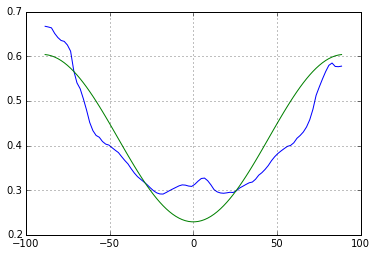

*Horizontal axis: latitude (°). Vertical axis: planetary albedo. Blue: NCEP-based estimate; green: prescribed profile.*

**Outgoing infrared:** $\mathrm{OLR}=A+BT$, with $A=210$ W m⁻² and $B=2$ W m⁻² K⁻¹, using $T$ in °C. This linear approximation relates surface temperature to radiation escaping to space after atmospheric absorption and emission. $A$ gives OLR at 0°C, and $B$ gives its increase per degree of warming. A 1°C warming increases OLR by 2 W m⁻², so warmer bands lose more energy through radiation.

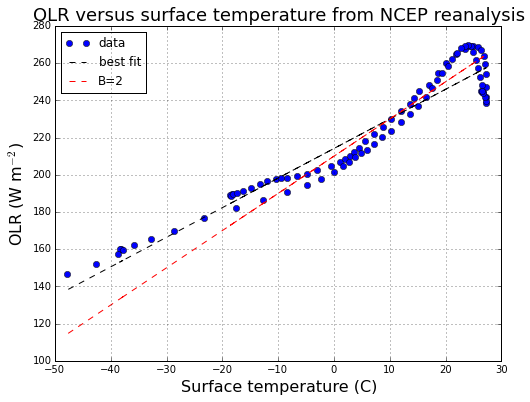

*Each blue point represents one latitude's annual mean temperature and OLR. Their approximately linear relationship motivates this approximation. The red dashed line is our chosen $210+2T$; the black dashed line is the best fit to these data.*

We keep the horizontal heat transport from Section 3 unchanged.

In [ ]:
A, B = 210.0, 2.0
albedo = 0.229 + 0.375*np.sin(phi)**2
ASR = (1 - albedo)*Q

def olr(T):
    return A + B*np.asarray(T)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
axes[0].plot(lat, Q, label='Incoming sunlight Q', color='#777777', lw=2)
axes[0].plot(lat, ASR, label='Absorbed sunlight ASR', color='#c54b26', lw=2)
axes[0].set(xlabel='Latitude (°)', ylabel='Solar flux (W/m²)', xlim=(-90, 90))
axes[0].legend()
axes[1].plot(lat, albedo, color='#2374a5', lw=2)
axes[1].set(xlabel='Latitude (°)', ylabel='Prescribed planetary albedo',
            xlim=(-90, 90), ylim=(0, 0.7))
FIGURES['inputs'] = fig
plt.show()
print(f'Area-weighted incoming sunlight: {global_mean(Q):.2f} W/m²')
print(f'Area-weighted absorbed sunlight: {global_mean(ASR):.2f} W/m²')

Compare the latitude dependence of incoming sunlight, absorbed sunlight, and prescribed albedo in the plots above.

<a id="response-4"></a>

**Lab questions**

Why is the equator-to-pole difference in ASR stronger than the difference in incoming sunlight alone?

**Answer:** [Your answer here.]

### Supplied time stepping

The next function advances temperatures through time using the same energy budget as the **explicit time stepping** we learned earlier. Here we use an **implicit** method: each update solves for all bands' new temperatures together. This allows larger stable time steps than explicit stepping for diffusion, so we can reach equilibrium with fewer steps. We use 5-day steps.

The settings to change are `D`, `water_depth`, and the initial temperature. `radiation=False` turns **both** ASR and OLR off, isolating redistribution. You do not need to edit the solver.

In [ ]:
def simulate(D=0.6, years=15.0, water_depth=10.0,
             initial=10.0, radiation=True, dt_days=5.0):
    if not np.all(np.isfinite([D, years, water_depth, dt_days])):
        raise ValueError('Use finite parameters.')
    if D < 0 or min(years, water_depth, dt_days) <= 0:
        raise ValueError('D must be nonnegative; time and depth must be positive.')
    C = RHO_CP*water_depth
    start = np.broadcast_to(np.asarray(initial, dtype=float), lat.shape).copy()
    if not np.all(np.isfinite(start)):
        raise ValueError('Initial temperatures must be finite.')
    nstep = int(np.ceil(years*365.25/dt_days))
    time = np.linspace(0.0, years, nstep + 1)
    dt = (time[1]-time[0])*SECONDS_PER_YEAR
    operator = D*L - (B*np.eye(len(lat)) if radiation else 0)
    source = ASR - A if radiation else np.zeros_like(ASR)
    factor = lu_factor(np.eye(len(lat)) - dt/C*operator)
    T = np.empty((nstep + 1, len(lat)))
    T[0] = start
    for n in range(nstep):
        T[n+1] = lu_solve(factor, T[n] + dt/C*source)
    return dict(time=time, T=T, C=C, D=D, radiation=radiation,
                water_depth=water_depth, dt_seconds=dt)

def profiles(ax, run, times):
    for target in times:
        i = np.argmin(np.abs(run['time']-target))
        ax.plot(lat, run['T'][i], label=f"{run['time'][i]:.2g} yr", lw=2)
    ax.set(xlabel='Latitude (°)', ylabel='Temperature (°C)', xlim=(-90, 90))
    ax.legend(fontsize=9)

## 5. Isolate diffusion (optional)

Start with a smooth warm-equator, cold-pole profile:
$$T(\phi,0)=32-60\sin^2\phi\quad[{}^\circ\mathrm C].$$

Turn radiation off.

In [ ]:
initial_profile = 32.0 - 60.0*np.sin(phi)**2
diffusion_run = simulate(D=0.6, years=3, initial=initial_profile, radiation=False)
fig, ax = plt.subplots(figsize=(7, 4.4), layout='constrained')
profiles(ax, diffusion_run, [0, 1/12, 0.25, 0.5, 1, 3])
ax.set_title('Redistribution alone: no radiation')
FIGURES['diffusion_only'] = fig
plt.show()
means = global_mean(diffusion_run['T'])
print(f'Initial global mean: {means[0]:.4f} °C')
print(f'Final global mean:   {means[-1]:.4f} °C')
print(f'Maximum mean change: {np.max(np.abs(means-means[0])):.2e} K')

<a id="response-5"></a>

**Lab questions**

What happens to the temperature profile when diffusion acts alone?

**Answer:** [Your answer here.]

## 6. Run the refined EBM

The refined EBM combines **absorbed sunlight** $\mathrm{ASR}=[1-\mathcal A(\phi)]Q(\phi)$ using latitude-dependent albedo, **outgoing infrared** $\mathrm{OLR}=210+2T$ with $T$ in °C, and **heating from horizontal transport** $h$:

$$C\frac{dT}{dt}=[1-\mathcal A(\phi)]Q(\phi)-(210+2T)+h.$$

We now include radiation again after the optional diffusion-only experiment. Start every band at 10°C. First run without transport ($D=0$), then with transport ($D=0.6$ W m⁻² K⁻¹).

In [ ]:
no_transport = simulate(D=0.0)
baseline = simulate(D=0.6)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True, layout='constrained')
for ax, run, title in zip(axes, [no_transport, baseline],
                        ['Radiation alone (D = 0)', 'Radiation and transport (D = 0.6)']):
    profiles(ax, run, [0, 0.25, 1, 3, 15])
    ax.set_title(title)
FIGURES['adjustment'] = fig
plt.show()

<a id="response-6"></a>

**Lab questions**

Why are the tropics cooler at equilibrium with heat transport than at equilibrium without it?

**Answer:** [Your answer here.]

## 7. Check the local budget

Look at the final budget of the $D=0.6$ run. The local storage rate is

$$\frac{dE_i}{dt}=C\frac{dT_i}{dt}=\underbrace{\mathrm{ASR}_i-\mathrm{OLR}_i}_{N_i}+h_i.$$

In [ ]:
T_final = baseline['T'][-1]
H, h = transport(T_final, D=baseline['D'])
N = ASR - olr(T_final)
storage = N + h
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
axes[0].plot(lat, N, label='Net radiation N = ASR − OLR', color='#c54b26', lw=2)
axes[0].plot(lat, h, label='Transport heating h', color='#2374a5', lw=2)
axes[0].plot(lat, storage, label='Storage rate N + h', color='#555555', ls='--', lw=2)
axes[0].axhline(0, color='black', lw=0.7)
axes[0].set(xlabel='Latitude (°)', ylabel='Energy flux (W/m²)', xlim=(-90, 90))
axes[0].legend(fontsize=9)
axes[1].plot(lat_edges, H/1e15, color='#7b4397', lw=2)
axes[1].axhline(0, color='black', lw=0.7)
axes[1].set(xlabel='Boundary latitude (°)', ylabel='Northward heat transport H (PW)',
            xlim=(-90, 90))
FIGURES['budgets'] = fig
plt.show()
print(f'Maximum absolute local storage rate: {np.max(np.abs(storage)):.3e} W/m²')
print(f'Global mean transport heating:      {global_mean(h):.3e} W/m²')
print(f'Global mean net radiation:          {global_mean(N):.3e} W/m²')

**What the printed numbers mean:** All three are in W m⁻².

- **Maximum absolute local storage rate:** the largest $|N+h|$ among all latitude bands. Its tiny value confirms that temperatures have nearly stopped changing everywhere.
- **Global mean transport heating:** the area-weighted mean of $h$. It is zero because transport redistributes energy between bands and conserves the total.
- **Global mean net radiation:** the area-weighted mean of $N$. Its tiny value shows that the planet's total absorbed sunlight balances its outgoing infrared radiation at equilibrium.

Values such as `3.895e-10` mean $3.895\times10^{-10}$, effectively zero here. The small remainders come from finite numerical precision and approaching equilibrium.

**Reading the figure:**

- **Left panel:** The tropics gain energy from radiation ($N>0$) and lose it through transport ($h<0$). High latitudes lose energy through radiation ($N<0$) and gain it through transport ($h>0$). The two terms cancel, so the dashed storage rate $N+h$ is approximately zero everywhere.
- **Right panel:** Heat moves toward both poles: $H<0$ means southward transport in the Southern Hemisphere, and $H>0$ means northward transport in the Northern Hemisphere.

**Takeaway:** At equilibrium, temperatures stay steady while radiation and heat transport continue. Each latitude balances its radiative gain or loss with heat exported or imported by transport.

<a id="response-7"></a>

**Lab questions**

What should the local storage rate $N+h$ be when the model reaches equilibrium?

**Answer:** [Your answer here.]

## 8. Change transport strength

Keep radiation and heat capacity fixed.

We report the contrast between the **1°N and 89°N band centers**, not an exact point temperature at the equator or pole.

In [ ]:
transport_values = [0.0, 0.1, 0.6, 1.2]
runs = {D: no_transport if D == 0 else baseline if D == 0.6 else simulate(D=D)
        for D in transport_values}
fig, ax = plt.subplots(figsize=(7.2, 4.4), layout='constrained')
print('D (W/m²/K)   mean (°C)   contrast (K)   max |H| (PW)')
equator_band = len(lat)//2
for D, run in runs.items():
    T = run['T'][-1]
    H_D, _ = transport(T, D)
    ax.plot(lat, T, label=f'D = {D:g}', lw=2)
    contrast = T[equator_band] - T[-1]
    print(f'{D:10.1f}   {global_mean(T):9.3f}   {contrast:12.3f}   {np.max(np.abs(H_D))/1e15:12.3f}')
ax.set(xlabel='Latitude (°)', ylabel='Final temperature (°C)', xlim=(-90, 90))
ax.legend()
FIGURES['transport_strength'] = fig
plt.show()

<a id="response-8"></a>

**Lab questions**

What happens to the equator-to-pole temperature difference as $D$ increases?

**Answer:** [Your answer here.]

### Sources and modeling choices

- [Brian E. J. Rose, Lecture 14: The one-dimensional energy balance model](https://www.atmos.albany.edu/facstaff/brose/classes/ATM623_Spring2015/Notes/Lectures/Lecture14%20--%20Diffusive%20energy%20balance%20model.html): radiation and diffusion parameterizations, reference coefficients, and experiment sequence. The NCEP-based albedo comparison and OLR–surface-temperature figures in Section 4 are reproduced from this lecture, as in the class slides.
- [climlab solar geometry documentation](https://climlab.readthedocs.io/en/latest/api/climlab.solar.insolation.html): daily and annual insolation calculations. Our short solar helper uses daily geometry for a circular orbit, with axial tilt 23.44° and $S_0=1361$ W m⁻².

The notebook uses NumPy and SciPy directly, so the model runs without climlab. Public data are read from the local cache, with downloads only if a file is missing. It preserves spherical geometry through boundary circumference factors and exact band areas. The code integrates in time to find equilibrium. The initial profile and albedo are written directly with $\sin^2\phi$.

- [NOAA PSL temperature climatology](https://psl.noaa.gov/thredds/catalog/Datasets/ncep.reanalysis.derived/surface_gauss/catalog.html?dataset=Datasets%2Fncep.reanalysis.derived%2Fsurface_gauss%2Fskt.sfc.mon.1981-2010.ltm.nc): NCEP–NCAR Reanalysis 1 skin temperature, 1981–2010, already in °C.

Both radiation models use S0=1361 W/m². The gray runs use adaptive BDF integration; the linear runs use backward Euler. In each radiative run equilibrium is obtained by time integration.

- [NASA CERES](https://ceres.larc.nasa.gov/science/): unchanged net TOA radiation figure, EBAF Ed2.6r, March 2000–June 2011. This is the main radiation-budget comparison. [Edition 2.6r documentation](https://ceres.larc.nasa.gov/documents/cmip5-data/Tech-Note_rsdt_CERES-EBAF_L3B_Ed2-6r_20121101.pdf) describes the global heat-storage constraint.

- [British Antarctic Survey: Temperatures in Antarctica](https://legacy.bas.ac.uk/about_antarctica/geography/weather/temperatures.php): elevation contributes to the cold Antarctic interior; the regional model has no elevation dependence.
